# Manufacturing Performance & Predictive Analytics

This project uses synthetic production-order data to understand manufacturing delays and test whether machine learning can help identify orders at risk of delay.

## 1. Load the data

Upload the CSV files to the Colab file panel. The production-order file contains the fields used in this analysis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

data_folder = "/content"

production = pd.read_csv(
    data_folder + "/Manufacturing_Production_Orders.csv"
)

print("Rows and columns:", production.shape)
display(production.head())

Rows and columns: (2000, 26)


,Production_Order_ID,Product_ID,Product_Name,Product_Family,Plant_ID,Plant_Name,Work_Center_ID,Work_Center_Name,Supplier_ID,Supplier_Name,...,Capacity_Load_Pct,Changeover_Hours,Planned_Downtime_Hours,Actual_Start_Date,Actual_Completion_Date,Actual_Production_Days,Completed_Quantity,Scrap_Quantity,Actual_Downtime_Hours,Delayed_Flag
0,MFG-2024-000649,PRD-1021,Pump Impeller Housing,Fluid Handling,PLT-VAD,Vadodara Industrial Works,WC-MCH-04,Heavy Machining Centre,SUP-2001,Western Alloy Components,...,89.0,2.8,3.4,2024-01-01,2024-01-06,5,145,6,4.7,0
1,MFG-2024-000756,PRD-1027,Stainless Pump Connector,Fluid Handling,PLT-NSK,Nashik Assembly Facility,WC-ASM-07,Final Assembly Line,SUP-2002,Deccan Precision Castings,...,96.0,0.5,1.6,2024-01-01,2024-01-08,7,50,2,4.8,0
2,MFG-2024-000980,PRD-1017,CNC Machined Valve Body,Valve,PLT-VAD,Vadodara Industrial Works,WC-ASM-02,Hydraulic Assembly Line,SUP-2003,Summit Industrial Bearings,...,52.3,6.5,2.9,2024-01-01,2024-01-05,4,496,2,5.8,0
3,MFG-2024-001138,PRD-1012,Worm Gear Reducer Housing,Gearbox,PLT-NSK,Nashik Assembly Facility,WC-TST-05,Valve Testing Station,SUP-2008,BluePeak Industrial Fasteners,...,69.5,0.5,0.1,2024-01-02,2024-01-12,11,100,1,3.9,1
4,MFG-2024-001978,PRD-1011,Precision Bearing Carrier,Power Transmission,PLT-AHM,Ahmedabad Components Works,WC-ASM-02,Hydraulic Assembly Line,SUP-2007,Everstone Engineering Materials,...,76.3,0.5,1.0,2024-01-01,2024-01-16,15,150,1,4.6,1


## 2. Check the data

First, check for duplicate order IDs, missing values, and the distribution of the delay flag. The target column is `Delayed_Flag`, where 1 means delayed and 0 means not delayed.

In [2]:
print("Duplicate order IDs:", production["Production_Order_ID"].duplicated().sum())

print("\nMissing values:")
print(production.isnull().sum())

print("\nDelay flag counts:")
print(production["Delayed_Flag"].value_counts())

print("\nDelay flag percentage:")
print((production["Delayed_Flag"].value_counts(normalize=True) * 100).round(2))

Duplicate order IDs: 0

Missing values:
Production_Order_ID        0
Product_ID                 0
Product_Name               0
Product_Family             0
Plant_ID                   0
Plant_Name                 0
Work_Center_ID             0
Work_Center_Name           0
Supplier_ID                0
Supplier_Name              0
Order_Priority             0
Planned_Start_Date         0
Planned_Completion_Date    0
Planned_Production_Days    0
Planned_Quantity           0
Material_Delay_Days        0
Capacity_Load_Pct          0
Changeover_Hours           0
Planned_Downtime_Hours     0
Actual_Start_Date          0
Actual_Completion_Date     0
Actual_Production_Days     0
Completed_Quantity         0
Scrap_Quantity             0
Actual_Downtime_Hours      0
Delayed_Flag               0
dtype: int64

Delay flag counts:
Delayed_Flag
0    1548
1     452
Name: count, dtype: int64

Delay flag percentage:
Delayed_Flag
0    77.4
1    22.6
Name: proportion, dtype: float64


## 3. Explore production delays

Compare delay rates across plants, product families, order priorities, material delays, and capacity-load groups. These results describe patterns in this synthetic dataset; they do not prove that one factor causes a delay.

In [3]:
delay_summary = production.groupby("Delayed_Flag").agg(
    Production_Orders=("Production_Order_ID", "count"),
    Average_Planned_Days=("Planned_Production_Days", "mean"),
    Average_Completed_Quantity=("Completed_Quantity", "mean"),
    Average_Downtime_Hours=("Actual_Downtime_Hours", "mean")
).round(2)

display(delay_summary)

,Production_Orders,Average_Planned_Days,Average_Completed_Quantity,Average_Downtime_Hours
Delayed_Flag,,,,
0,1548,5.85,289.01,4.64
1,452,6.51,270.21,7.57


In [4]:
plant_delay = production.groupby("Plant_Name").agg(
    Total_Orders=("Production_Order_ID", "count"),
    Delayed_Orders=("Delayed_Flag", "sum")
)

plant_delay["Delay_Rate_Pct"] = (
    plant_delay["Delayed_Orders"] / plant_delay["Total_Orders"] * 100
).round(2)

display(plant_delay.sort_values("Delay_Rate_Pct", ascending=False))

,Total_Orders,Delayed_Orders,Delay_Rate_Pct
Plant_Name,,,
Ahmedabad Components Works,583,137,23.50
Nashik Assembly Facility,480,112,23.33
Pune Precision Engineering Plant,561,124,22.10
Vadodara Industrial Works,376,79,21.01


In [5]:
family_delay = production.groupby("Product_Family").agg(
    Total_Orders=("Production_Order_ID", "count"),
    Delayed_Orders=("Delayed_Flag", "sum")
)

family_delay["Delay_Rate_Pct"] = (
    family_delay["Delayed_Orders"] / family_delay["Total_Orders"] * 100
).round(2)

display(family_delay.sort_values("Delay_Rate_Pct", ascending=False))

,Total_Orders,Delayed_Orders,Delay_Rate_Pct
Product_Family,,,
Pneumatic,136,37,27.21
Valve,141,38,26.95
Rotating Equipment,68,16,23.53
Automation,68,16,23.53
Metal Components,56,13,23.21
Fluid Handling,208,48,23.08
Structural Components,191,44,23.04
Hydraulic,259,57,22.01
Power Transmission,457,98,21.44


In [6]:
priority_delay = production.groupby("Order_Priority").agg(
    Total_Orders=("Production_Order_ID", "count"),
    Delayed_Orders=("Delayed_Flag", "sum")
)

priority_delay["Delay_Rate_Pct"] = (
    priority_delay["Delayed_Orders"] / priority_delay["Total_Orders"] * 100
).round(2)

display(priority_delay.sort_values("Delay_Rate_Pct", ascending=False))

,Total_Orders,Delayed_Orders,Delay_Rate_Pct
Order_Priority,,,
Routine,307,92,29.97
Standard,929,212,22.82
High,583,115,19.73
Critical,181,33,18.23


In [7]:
material_delay = production.groupby("Material_Delay_Days").agg(
    Total_Orders=("Production_Order_ID", "count"),
    Delayed_Orders=("Delayed_Flag", "sum")
)

material_delay["Delay_Rate_Pct"] = (
    material_delay["Delayed_Orders"] / material_delay["Total_Orders"] * 100
).round(2)

display(material_delay)

,Total_Orders,Delayed_Orders,Delay_Rate_Pct
Material_Delay_Days,,,
0,1204,213,17.69
1,294,58,19.73
2,213,60,28.17
3,110,36,32.73
5,123,56,45.53
7,56,29,51.79


In [8]:
production["Capacity_Load_Band"] = pd.cut(
    production["Capacity_Load_Pct"],
    bins=[0, 60, 75, 90, 120],
    labels=["Below 60%", "60–75%", "75–90%", "Above 90%"],
    include_lowest=True
)

capacity_delay = production.groupby("Capacity_Load_Band", observed=False).agg(
    Total_Orders=("Production_Order_ID", "count"),
    Delayed_Orders=("Delayed_Flag", "sum")
)

capacity_delay["Delay_Rate_Pct"] = (
    capacity_delay["Delayed_Orders"] / capacity_delay["Total_Orders"] * 100
).round(2)

display(capacity_delay)

,Total_Orders,Delayed_Orders,Delay_Rate_Pct
Capacity_Load_Band,,,
Below 60%,186,28,15.05
60–75%,641,100,15.60
75–90%,821,216,26.31
Above 90%,352,108,30.68


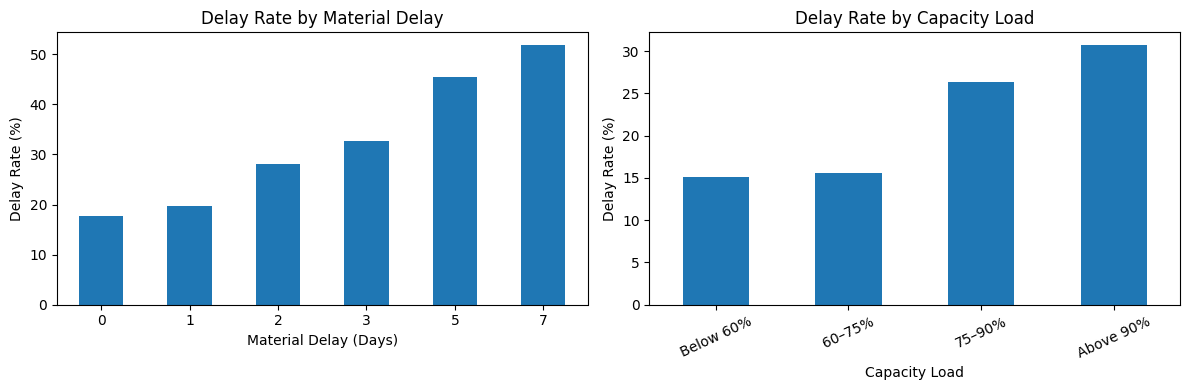

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

material_delay["Delay_Rate_Pct"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Delay Rate by Material Delay")
axes[0].set_xlabel("Material Delay (Days)")
axes[0].set_ylabel("Delay Rate (%)")
axes[0].tick_params(axis="x", rotation=0)

capacity_delay["Delay_Rate_Pct"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Delay Rate by Capacity Load")
axes[1].set_xlabel("Capacity Load")
axes[1].set_ylabel("Delay Rate (%)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

## 4. Prepare the model data

Use fields that could be available while a production order is being planned or monitored, before the final completion result is known. Actual completion dates, actual production days, completed quantity, scrap, and actual downtime are not used as model inputs because they can reveal information from after production.

Material delay and capacity load are included as inputs, so the model represents an order-risk check when these values are available.

In [10]:
feature_columns = [
    "Product_Family",
    "Plant_Name",
    "Work_Center_Name",
    "Supplier_Name",
    "Order_Priority",
    "Planned_Production_Days",
    "Planned_Quantity",
    "Material_Delay_Days",
    "Capacity_Load_Pct",
    "Changeover_Hours",
    "Planned_Downtime_Hours"
]

model_data = production[feature_columns + ["Delayed_Flag"]].copy()

print("Model dataset shape:", model_data.shape)
print("\nMissing values in model data:")
print(model_data.isnull().sum())

print("\nDelay flag counts:")
print(model_data["Delayed_Flag"].value_counts())

Model dataset shape: (2000, 12)

Missing values in model data:
Product_Family             0
Plant_Name                 0
Work_Center_Name           0
Supplier_Name              0
Order_Priority             0
Planned_Production_Days    0
Planned_Quantity           0
Material_Delay_Days        0
Capacity_Load_Pct          0
Changeover_Hours           0
Planned_Downtime_Hours     0
Delayed_Flag               0
dtype: int64

Delay flag counts:
Delayed_Flag
0    1548
1     452
Name: count, dtype: int64


## 5. Split the data

Use a stratified 80/20 split so that both training and test data contain a similar share of delayed orders. The test set is kept aside for model evaluation.

In [11]:
X = model_data.drop(columns=["Delayed_Flag"])
y = model_data["Delayed_Flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1600
Test rows: 400


## 6. Train the models

The categorical fields are converted into numeric columns with one-hot encoding. Numeric fields are scaled for Logistic Regression. A simple baseline is included to show how the models compare with predicting the most common class every time.

In [12]:
categorical_features = X.select_dtypes(include="object").columns.tolist()
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numbers", StandardScaler(), numerical_features)
])

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=3000))
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

baseline_model.fit(X_train, y_train)
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


## 7. Compare model results

The delay flag is less common than the non-delayed class. For that reason, accuracy alone is not enough. Precision measures how many flagged orders were delayed, while recall measures how many delayed orders were found.

In [13]:
models = {
    "Baseline": baseline_model,
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for model_name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_test, predictions), 3),
        "Precision": round(precision_score(y_test, predictions, zero_division=0), 3),
        "Recall": round(recall_score(y_test, predictions, zero_division=0), 3),
        "F1_Score": round(f1_score(y_test, predictions, zero_division=0), 3)
    })

model_results = pd.DataFrame(results)
display(model_results.sort_values("F1_Score", ascending=False))

,Model,Accuracy,Precision,Recall,F1_Score
1,Logistic Regression,0.777,0.524,0.122,0.198
2,Random Forest,0.777,1.000,0.011,0.022
0,Baseline,0.775,0.000,0.000,0.000


## 8. Check different thresholds

Logistic Regression returns a probability for each order. A lower threshold flags more orders as potentially delayed, which can improve recall but also create more false alarms. These threshold results are exploratory and should not be used as an operational rule without further validation.

In [14]:
delay_probabilities = logistic_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.50, 0.40, 0.30, 0.20, 0.10]:
    predictions = (delay_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Predicted_Delays": int(predictions.sum()),
        "Precision": round(precision_score(y_test, predictions, zero_division=0), 3),
        "Recall": round(recall_score(y_test, predictions, zero_division=0), 3),
        "F1_Score": round(f1_score(y_test, predictions, zero_division=0), 3)
    })

threshold_results = pd.DataFrame(threshold_results)
display(threshold_results)

,Threshold,Predicted_Delays,Precision,Recall,F1_Score
0,0.5,21,0.524,0.122,0.198
1,0.4,52,0.462,0.267,0.338
2,0.3,104,0.365,0.422,0.392
3,0.2,210,0.305,0.711,0.427
4,0.1,354,0.237,0.933,0.378


,Predicted Not Delayed,Predicted Delayed
Actual Not Delayed,164,146
Actual Delayed,26,64


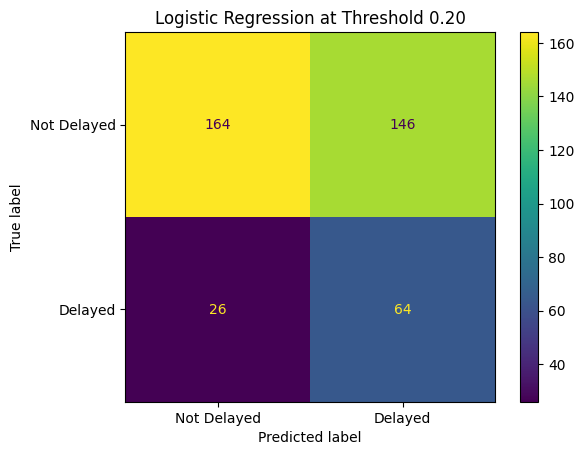

In [15]:
threshold = 0.20
predictions_020 = (delay_probabilities >= threshold).astype(int)

cm = confusion_matrix(y_test, predictions_020)

display(pd.DataFrame(
    cm,
    index=["Actual Not Delayed", "Actual Delayed"],
    columns=["Predicted Not Delayed", "Predicted Delayed"]
))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Delayed", "Delayed"]
).plot()

plt.title("Logistic Regression at Threshold 0.20")
plt.show()

## 9. Review Logistic Regression coefficients

The coefficients show how the model's predictions are associated with each encoded input, with other model inputs considered. They are not proof of causation and should not be treated as a universal ranking of business importance.

In [16]:
encoded_features = logistic_model.named_steps["preprocessor"].get_feature_names_out()
coefficients = logistic_model.named_steps["model"].coef_[0]

coefficient_results = pd.DataFrame({
    "Feature": encoded_features,
    "Coefficient": coefficients
})

coefficient_results["Absolute_Coefficient"] = coefficient_results["Coefficient"].abs()
coefficient_results = coefficient_results.sort_values(
    "Absolute_Coefficient", ascending=False
)

display(coefficient_results.head(15))

,Feature,Coefficient,Absolute_Coefficient
39,categories__Order_Priority_Routine,0.507401,0.507401
43,numbers__Material_Delay_Days,0.460037,0.460037
44,numbers__Capacity_Load_Pct,0.405962,0.405962
26,categories__Supplier_Name_BluePeak Industrial ...,0.402028,0.402028
34,categories__Supplier_Name_Summit Industrial Be...,0.394178,0.394178
7,categories__Product_Family_Metal Components,-0.379791,0.379791
8,categories__Product_Family_Pneumatic,0.361554,0.361554
41,numbers__Planned_Production_Days,0.294545,0.294545
37,categories__Order_Priority_Critical,-0.286600,0.286600
20,categories__Work_Center_Name_Heavy Machining C...,0.251944,0.251944


## 10. Save the results

The three files below contain the model comparison, threshold analysis, and Logistic Regression coefficients.

In [17]:
model_results.to_csv("model_comparison.csv", index=False)
threshold_results.to_csv("threshold_analysis.csv", index=False)
coefficient_results.to_csv("feature_coefficients.csv", index=False)

print("Result files saved.")

Result files saved.


## 11. Business takeaways

- Review material availability and delays before production starts.
- Investigate work centers and orders with high capacity loads.
- Compare plant-level delay rates and check for operational differences before deciding on corrective action.
- Use model flags to support planner review, not to make automatic production decisions.